# Controllable Image Generation: Garden Makeover

## Introduction

This task is **controllable image generation**: turn a real garden photograph into a new design while preserving its main structures.

You will first run a pretrained **Stable Diffusion 1.5 + Canny ControlNet** baseline. Then you will implement image preprocessing, reproducible experiment settings and edge-based evaluation in **Q1**, compare the effects of editing strength and structural control in **Q2**, and analyse failures and design choices in **Q3–Q4**.

You use pretrained inference; you do not train a diffusion model from scratch. Applications include landscape concept design and visual prototyping.

### Dataset — real garden photographs

The notebook embeds one real photograph from the **garden** scene of [Mip-NeRF 360](https://jonbarron.info/mipnerf360/). No separate data upload is required. Every experiment uses the same 512 × 336 crop.

**Fixed comparison:** two image-to-image strengths `[0.50, 0.80]` × three ControlNet scales `[0.0, 0.5, 1.0]`, with the same prompt, seed and sampler settings.

### Evaluation metrics

We report **edge precision**, **edge recall** and **edge F1** with a 2-pixel matching tolerance. These measure structural agreement, not beauty or prompt compliance.

$$P=\frac{\text{output edges near an input edge}}{\text{output edges}},\quad R=\frac{\text{input edges near an output edge}}{\text{input edges}}$$
$$F_1=\frac{2PR}{P+R}$$

The evaluator uses the same Canny extraction as the conditioning signal. Assess visual quality separately by inspecting tabletop geometry, the vase, materials and artefacts.

## Submission

Please submit:

- Your completed `tutorial10_generative_vision_STUDENT.ipynb`, with outputs visible
- `garden_makeover_submission.zip`, containing the baseline images, metrics and run record
- `question_results.zip`, created by the final export cell and containing your additional tables and figures

**Checklist**

* All `###YOUR CODE HERE###` sections in Q1–Q3 are completed
* Short written answers in **Q1–Q4** are completed
* Total points: **100**; all questions are required

Keep the question numbers and section headings in your submission.

---

## Before starting — runnable tutorial

1. Select a **T4 GPU** runtime before running any cells or uploading data. Use a separate Colab runtime for each tutorial, so their output folders do not mix.
2. On the first pass, run the baseline cells in order and **stop before Q1**. Do not use **Run all** on the unfinished student notebook: its exercise placeholders intentionally raise errors.
3. Fill each `###YOUR CODE HERE###` section, replacing its `None` or `NotImplementedError`, then run Q1–Q4 in order. Reuse the baseline outputs; do not repeat model training or generation for the questions.

Download your completed notebook and both result ZIPs before ending the session. A kernel restart clears variables; recycling the VM also deletes local files.

After a kernel restart with files still present, use **Restore after a kernel restart** immediately before Q1; you do not need to generate new images.

### Install dependencies

Select a **T4 GPU** runtime in Colab. Allow about 8 minutes for initial installation and model loading; download time varies.

In [1]:
import sys, subprocess, time, json, platform
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
 'diffusers==0.35.1', 'transformers==4.57.1', 'accelerate==1.10.1',
 'safetensors==0.6.2', 'opencv-python-headless==4.11.0.86',
 'pandas', 'matplotlib'], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'diffusers==0.35.1', 'transformers==4.57.1', 'accelerate==1.10.1', 'safetensors==0.6.2', 'opencv-python-headless==4.11.0.86', 'pandas', 'matplotlib'], returncode=0)

### Imports

In [2]:
from pathlib import Path
import io, base64, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2, torch
from IPython.display import display
OUT = Path('garden_makeover'); OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version(), 'Torch:', torch.__version__)
GPU = torch.cuda.is_available()
print('GPU:', torch.cuda.get_device_name(0) if GPU else 'Not allocated — input analysis only')

Python: 3.13.16 Torch: 2.14.1+cu130
GPU: Tesla T4


### Dataset paths

The photograph is embedded below. Generated files are saved under `garden_makeover/`. Keep the same input crop for every condition.

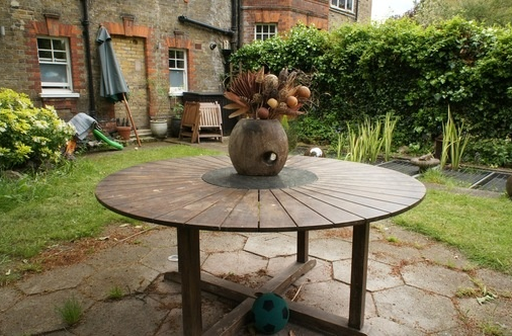

In [3]:
PHOTO_B64 = '...'
raw_photo = Image.open(io.BytesIO(base64.b64decode(PHOTO_B64))).convert('RGB')
# Fit once to dimensions divisible by 8; use this identical crop in every arm.
source = ImageOps.fit(raw_photo, (512, 336), method=Image.Resampling.LANCZOS)
source.save(OUT / 'input.png')
display(source)

#### Visualize the photograph and its control signal

Canny uses RGB-to-grayscale conversion, 5 × 5 Gaussian smoothing and thresholds 100/200.

In [4]:
def edge_map(image, low=100, high=200):
    gray = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 1.0)
    return cv2.Canny(gray, low, high)

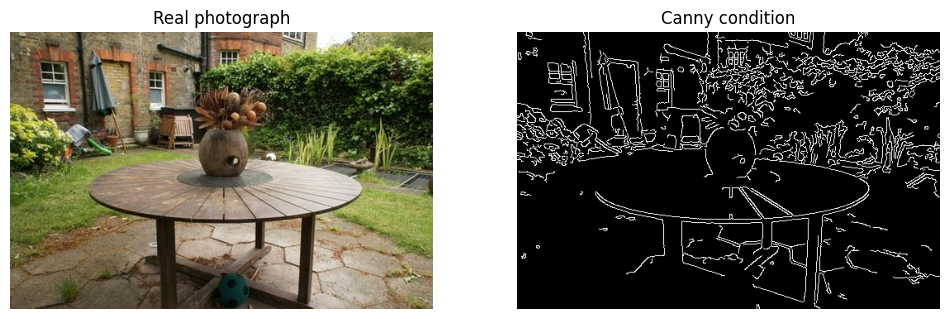

In [5]:
edges = edge_map(source)
assert edges.shape == (336, 512) and edges.dtype == np.uint8
assert 0 < np.count_nonzero(edges) < edges.size
control = Image.fromarray(np.repeat(edges[..., None], 3, axis=2))
control.save(OUT / 'control.png')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, im, title in zip(ax, [source, control], ['Real photograph', 'Canny condition']):
    a.imshow(im); a.set_title(title); a.axis('off')
plt.show()

### Runnable baseline: pretrained image-to-image diffusion

The model revisions below are fixed. Keep the safety checker enabled. Loading the weights is separate from image-generation time.

In [6]:
assert GPU, 'A CUDA GPU is needed for the generation section.'
from diffusers import ControlNetModel, StableDiffusionControlNetImg2ImgPipeline, UniPCMultistepScheduler
BASE_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
CONTROL_ID = 'lllyasviel/control_v11p_sd15_canny'
# Model revisions are fixed for this assignment; leave these values unchanged.
BASE_REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
CONTROL_REVISION = '115a470d547982438f70198e353a921996e2e819'
net = ControlNetModel.from_pretrained(CONTROL_ID, revision=CONTROL_REVISION, torch_dtype=torch.float16)
pipe = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    BASE_ID, revision=BASE_REVISION, controlnet=net, torch_dtype=torch.float16)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_model_cpu_offload()
pipe.enable_vae_slicing()
print(BASE_REVISION, CONTROL_REVISION)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/996 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

... (12 outputs left out)

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


451f4fe16113bff5a5d2269ed5ad43b0592e9a14 115a470d547982438f70198e353a921996e2e819


In [7]:
PROMPT = ('photograph of a beautiful Mediterranean garden courtyard, '
          'round wooden garden table with a flower vase, terracotta accents, '
          'lush climbing flowers, warm afternoon sunlight, natural materials, '
          'realistic architectural photography')
NEGATIVE = 'cartoon, illustration, blurry, distorted furniture, duplicate table, text, watermark'
SEED = 42
STEPS = 25
GUIDANCE = 7.5

### Generate a controlled comparison

Only strength and ControlNet scale are varied. Strength also changes the active denoising schedule/step count in img2img, so a between-row comparison is not an equal-compute comparison. A fresh generator with the same seed is created for each call.

In [8]:
strengths = [0.50, 0.80]
scales = [0.0, 0.5, 1.0]
configs = [(strength, scale) for strength in strengths for scale in scales]

In [9]:
assert len(configs) == 6 and len(set(configs)) == 6
assert set(configs) == {(a, b) for a in strengths for b in scales}

In [10]:
def new_generator(seed):
    return torch.Generator(device='cpu').manual_seed(seed)

In [11]:
assert torch.equal(torch.randn(4, generator=new_generator(SEED)),
                   torch.randn(4, generator=new_generator(SEED)))
images, rows = {}, []
for strength, scale in configs:
    torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); start = time.perf_counter()
    result = pipe(prompt=PROMPT, negative_prompt=NEGATIVE, image=source,
                  control_image=control, strength=strength,
                  controlnet_conditioning_scale=scale, num_inference_steps=STEPS,
                  guidance_scale=GUIDANCE, generator=new_generator(SEED))
    torch.cuda.synchronize(); elapsed = time.perf_counter() - start
    name = f'strength_{strength:.2f}_scale_{scale:.1f}'
    output = result.images[0]; output.save(OUT / f'{name}.png')
    images[(strength, scale)] = output
    flag = None if result.nsfw_content_detected is None else bool(result.nsfw_content_detected[0])
    rows.append(dict(name=name, strength=strength, control_scale=scale, seed=SEED,
                     seconds=elapsed, peak_allocated_GB=torch.cuda.max_memory_allocated()/1e9,
                     safety_flag=flag))
print('Saved', len(images), 'generated images.')

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Saved 6 generated images.


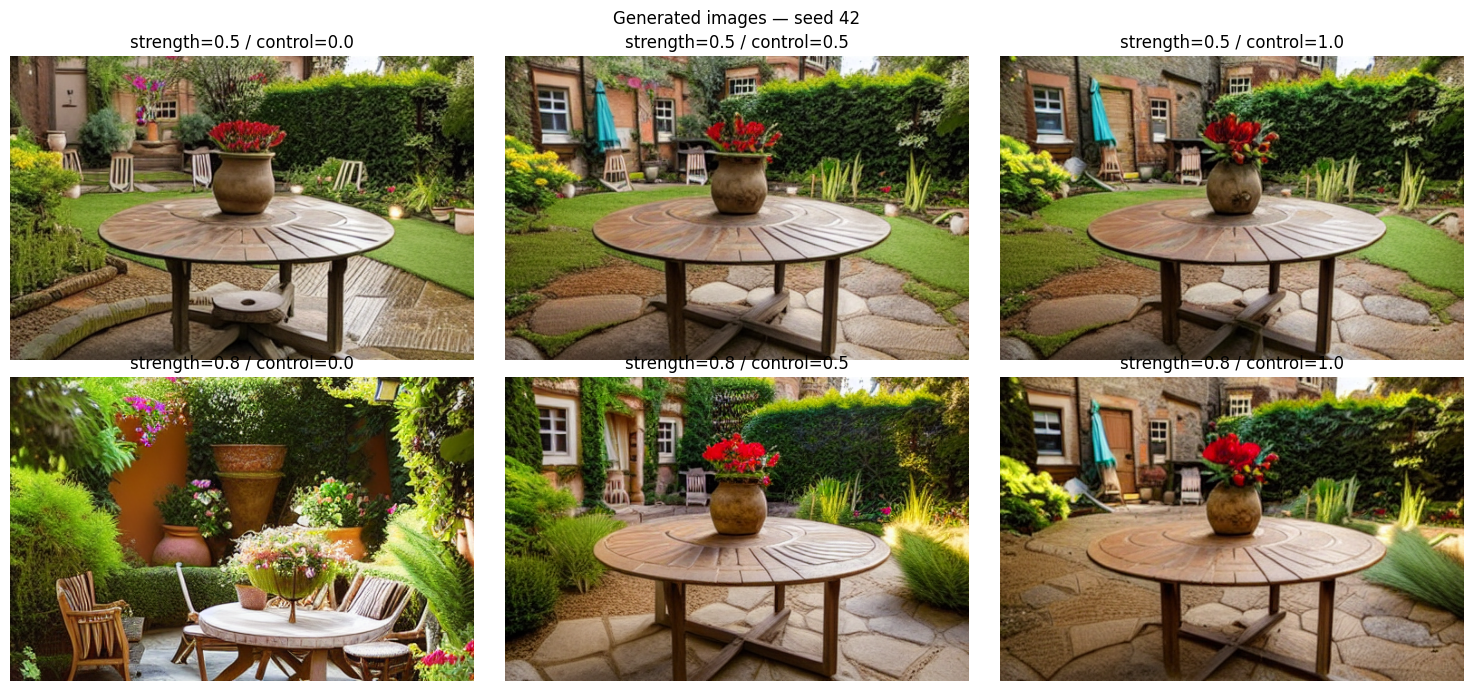

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for (strength, scale), a in zip(configs, ax.ravel()):
    a.imshow(images[(strength, scale)]); a.axis('off')
    a.set_title(f'strength={strength} / control={scale}')
fig.suptitle('Generated images — seed 42'); fig.tight_layout()
fig.savefig(OUT / 'comparison.png', dpi=150, bbox_inches='tight'); plt.show()

### Evaluate and save the baseline

Empty edge maps have undefined scores. The saved metrics include a tolerance sensitivity check; compare these numbers with the actual images.

In [13]:
def edge_scores(reference, prediction, radius=2):
    ref, pred = edge_map(reference) > 0, edge_map(prediction) > 0
    if not ref.any() or not pred.any(): return (np.nan, np.nan, np.nan)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
    near_ref = cv2.dilate(ref.astype('uint8'), kernel) > 0
    near_pred = cv2.dilate(pred.astype('uint8'), kernel) > 0
    precision = (pred & near_ref).sum() / pred.sum()
    recall = (ref & near_pred).sum() / ref.sum()
    f1 = 2*precision*recall / (precision+recall+1e-12)
    return float(precision), float(recall), float(f1)

In [14]:
assert np.allclose(edge_scores(source, source), (1, 1, 1))
for row, config in zip(rows, configs):
    row['precision'], row['recall'], row['edge_f1'] = edge_scores(source, images[config])
    row['f1_r1'] = edge_scores(source, images[config], radius=1)[2]
    row['f1_r3'] = edge_scores(source, images[config], radius=3)[2]
table = pd.DataFrame(rows); table.to_csv(OUT/'scores.csv', index=False)
display(table)

,name,strength,control_scale,seed,seconds,peak_allocated_GB,safety_flag,precision,recall,edge_f1,f1_r1,f1_r3
0,strength_0.50_scale_0.0,0.5,0.0,42,6.973026,3.371221,False,0.514754,0.545625,0.529740,0.374646,0.614314
1,strength_0.50_scale_0.5,0.5,0.5,42,4.604164,3.376641,False,0.697714,0.730481,0.713722,0.564746,0.775391
2,strength_0.50_scale_1.0,0.5,1.0,42,4.529112,3.379459,False,0.825020,0.858133,0.841251,0.722608,0.885059
3,strength_0.80_scale_0.0,0.8,0.0,42,5.506730,3.374839,False,0.385852,0.481695,0.428479,0.289281,0.503039
4,strength_0.80_scale_0.5,0.8,0.5,42,5.390940,3.375916,False,0.619583,0.570032,0.593776,0.448333,0.665609
5,strength_0.80_scale_1.0,0.8,1.0,42,5.532297,3.377985,False,0.873079,0.797601,0.833635,0.716355,0.878909


In [15]:
import importlib.metadata as md, shutil
run_card = dict(project='Garden Makeover',
    base_model=BASE_ID, base_revision=BASE_REVISION,
    control_model=CONTROL_ID, control_revision=CONTROL_REVISION,
    gpu=torch.cuda.get_device_name(0), torch=torch.__version__,
    versions={p: md.version(p) for p in ['diffusers','transformers','accelerate']},
    prompt=PROMPT, negative_prompt=NEGATIVE, seed=SEED, steps=STEPS,
    guidance=GUIDANCE, scheduler=type(pipe.scheduler).__name__,
    input_sha256=hashlib.sha256((OUT/'input.png').read_bytes()).hexdigest(),
    configurations=rows)
(OUT/'run_card.json').write_text(json.dumps(run_card, indent=2))
shutil.make_archive('garden_makeover_submission','zip',OUT)
print('Saved garden_makeover_submission.zip')

Saved garden_makeover_submission.zip


### Restore after a kernel restart

If the six images were already generated and `garden_makeover/` is still on disk, run the next cell directly, then run your completed question cells in order. This loads the saved images and metric helpers without loading diffusion weights or generating new images. Keep the whole folder or restore it by extracting `garden_makeover_submission.zip` into `garden_makeover/`. If an import is missing in a new VM, run **Install dependencies** first. A recycled VM loses local files; download a backup before ending the session.

In [16]:
# Recover existing images for the questions; no model loading or inference.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2, torch
from IPython.display import display

OUT = Path('garden_makeover')
assert (OUT/'run_card.json').is_file(), 'Restore the saved garden_makeover folder first.'
run_card = json.loads((OUT/'run_card.json').read_text())
rows = run_card['configurations']
configs = [(r['strength'], r['control_scale']) for r in rows]
assert configs == [(s, c) for s in [0.50, 0.80] for c in [0.0, 0.5, 1.0]]
source = Image.open(OUT/'input.png').convert('RGB')
images = {key: Image.open(OUT/f'strength_{key[0]:.2f}_scale_{key[1]:.1f}.png').convert('RGB')
          for key in configs}
assert all(im.size == source.size for im in images.values())
print('Restored the input and six saved outputs. Re-run your completed Q1–Q4 cells in order; no new generation is needed.')

def edge_map(image, low=100, high=200):
    gray = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 1.0)
    return cv2.Canny(gray, low, high)
def edge_scores(reference, prediction, radius=2):
    ref, pred = edge_map(reference) > 0, edge_map(prediction) > 0
    if not ref.any() or not pred.any(): return (np.nan, np.nan, np.nan)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
    near_ref = cv2.dilate(ref.astype('uint8'), kernel) > 0
    near_pred = cv2.dilate(pred.astype('uint8'), kernel) > 0
    precision = (pred & near_ref).sum() / pred.sum()
    recall = (ref & near_pred).sum() / ref.sum()
    f1 = 2*precision*recall / (precision+recall+1e-12)
    return float(precision), float(recall), float(f1)

Restored the input and six saved outputs. Re-run your completed Q1–Q4 cells in order; no new generation is needed.


---

## Q1 — Core implementation (42 pts)

Complete the missing code. Do **not** remove the `###YOUR CODE HERE###` markers. Use the runnable tutorial as a reference; the student functions below are separate from the baseline functions.

### Q1.1 Extract a structural condition (7 pts)

Fill **three lines** in `student_edge_map`:

1. Convert RGB to grayscale.
2. Apply a 5 × 5 Gaussian blur with sigma 1.
3. Run Canny with thresholds 100 and 200.

Return a 2-D `uint8` array. Hint: `cv2.cvtColor`, `cv2.GaussianBlur`, `cv2.Canny`.

In [17]:
def student_edge_map(image):
    gray = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2GRAY)  # ###YOUR CODE HERE###
    smooth = cv2.GaussianBlur(gray, (5, 5), 1.0)  # ###YOUR CODE HERE###
    return cv2.Canny(smooth, 100, 200)  # ###YOUR CODE HERE###
assert np.array_equal(student_edge_map(source), edge_map(source))
print('Edge-map check passed.')


Edge-map check passed.


### Q1.2 Construct the experiment grid (9 pts)

Complete the Cartesian product of **two strengths** and **three control scales**. Strength is the outer loop, so each row of the figure has a fixed strength. Do not change the prompt, input, seed or inference steps.

In [18]:
def student_configs(strength_values, control_values):
    return [(s, c) for s in strength_values for c in control_values]  # ###YOUR CODE HERE###
student_grid = student_configs([0.50, 0.80], [0.0, 0.5, 1.0])
assert student_grid == configs and len(set(student_grid)) == 6
print(student_grid)


[(0.5, 0.0), (0.5, 0.5), (0.5, 1.0), (0.8, 0.0), (0.8, 0.5), (0.8, 1.0)]


### Q1.3 Reproducible random generators (8 pts)

Fill the return statement to create a **new CPU generator** seeded with the supplied value. Creating one generator outside the loop would advance its state between conditions.

In [19]:
def student_generator(seed):
    return torch.Generator(device='cpu').manual_seed(seed)  # ###YOUR CODE HERE###
x = torch.randn(8, generator=student_generator(42))
y = torch.randn(8, generator=student_generator(42))
assert torch.equal(x, y)
assert not torch.equal(x, torch.randn(8, generator=student_generator(43)))
print('Seed checks passed.')


Seed checks passed.


### Q1.4 Implement edge precision, recall and F1 (15 pts)

Fill **three expressions** using the supplied tolerance masks. Precision divides by the number of **predicted** edges; recall divides by **reference** edges. Keep the empty-map handling provided below. Evaluate all six generated images without rerunning diffusion.

In [20]:
def student_edge_scores(reference, prediction, radius=2):
    ref = student_edge_map(reference) > 0
    pred = student_edge_map(prediction) > 0
    if not ref.any() or not pred.any():
        return np.nan, np.nan, np.nan
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1))
    near_ref = cv2.dilate(ref.astype('uint8'), kernel) > 0
    near_pred = cv2.dilate(pred.astype('uint8'), kernel) > 0
    precision = (pred & near_ref).sum() / pred.sum()  # ###YOUR CODE HERE###
    recall = (ref & near_pred).sum() / ref.sum()  # ###YOUR CODE HERE###
    f1 = 2 * precision * recall / (precision + recall + 1e-12)  # ###YOUR CODE HERE###
    return float(precision), float(recall), float(f1)
assert np.allclose(student_edge_scores(source, source), [1, 1, 1])
for key in configs:
    assert np.allclose(student_edge_scores(source, images[key]), edge_scores(source, images[key]), equal_nan=True)
print('Metric checks passed for all six outputs.')


Metric checks passed for all six outputs.


#### Q1.4 Reasoning — part of the 15 points

**Marking:** the three code expressions above carry **6 pts** total. Answer the following for the remaining **9 pts**:

1. If the prediction equals the input, what are edge F1 and RGB change, and why can this still fail the design brief? (3)
2. Why is an empty edge map undefined here rather than a perfect result? (3)
3. What different failure does low precision versus low recall indicate? (3)

**Your answer:**

1. **Identity output:** edge F1 = **1.0** and mean RGB change = **0.0** (the check `student_edge_scores(source, source) == (1,1,1)` confirms this). It still fails the brief because nothing was redesigned: no Mediterranean style, no terracotta, no climbing flowers. The metric rewards copying, so a perfect score can mean the generator ignored the prompt completely.
2. **Empty edge map:** precision = matched / predicted edges = 0/0, which is mathematically undefined. An empty map means the image has *no* structure at all (for example a blank or heavily blurred output). Returning 1.0 would reward destroying the image, so the function returns `NaN` to flag the case instead of hiding it.
3. **Low precision** means many output edges are *not* near an input edge: the model **added or hallucinated structure** (new chairs, pots, walls, busy texture). **Low recall** means many input edges have no output edge nearby: the model **lost or moved existing structure** (the table base or legs disappear or shift).

### Q1.5 Apply the same crop to both images (3 pts)

Fill the crop operation for the tabletop region. Use the same `(left, top, right, bottom)` coordinates for the real image and every output.

In [21]:
def student_crop(image, box):
    return image.crop(box)  # ###YOUR CODE HERE###
TABLE_BOX = (80, 100, 440, 320)
assert student_crop(source, TABLE_BOX).size == (360, 220)
print('Shared crop:', TABLE_BOX)


Shared crop: (80, 100, 440, 320)


---

## Q2 — Controlled comparison, metrics & robustness (30 pts)

**Q2.1** compares structural conditioning while holding strength fixed. **Q2.2** checks sensitivity to the metric tolerance. **Q2.3** is a short written question. Reuse the six baseline outputs; no additional GPU inference is needed.

### Q2.1 Controlled comparison — structure and amount of change (20 pts)

Complete three calculations: edge F1 (**4 pts**), its difference from the matched no-control result (**4 pts**) and mean absolute RGB change from the input (**4 pts**). Then interpret the edge-F1/change trade-off and one within-row visual observation (**8 pts**, written below).

RGB change is averaged over pixels and channels after scaling both images to [0,1]. A large value means more change, not necessarily a better image. The supplied plotting and CSV helpers carry no separate implementation marks.

**Control variable:** subtract the no-control result at the **same strength**. Do not use a result from the other row as the control.

,strength,control_scale,edge_f1,delta_vs_no_control,mean_rgb_change
0,0.5,0.0,0.529740,0.000000,0.125792
1,0.5,0.5,0.713722,0.183982,0.109580
2,0.5,1.0,0.841251,0.311511,0.097993
3,0.8,0.0,0.428479,0.000000,0.230945
4,0.8,0.5,0.593776,0.165296,0.158357
5,0.8,1.0,0.833635,0.405156,0.128568


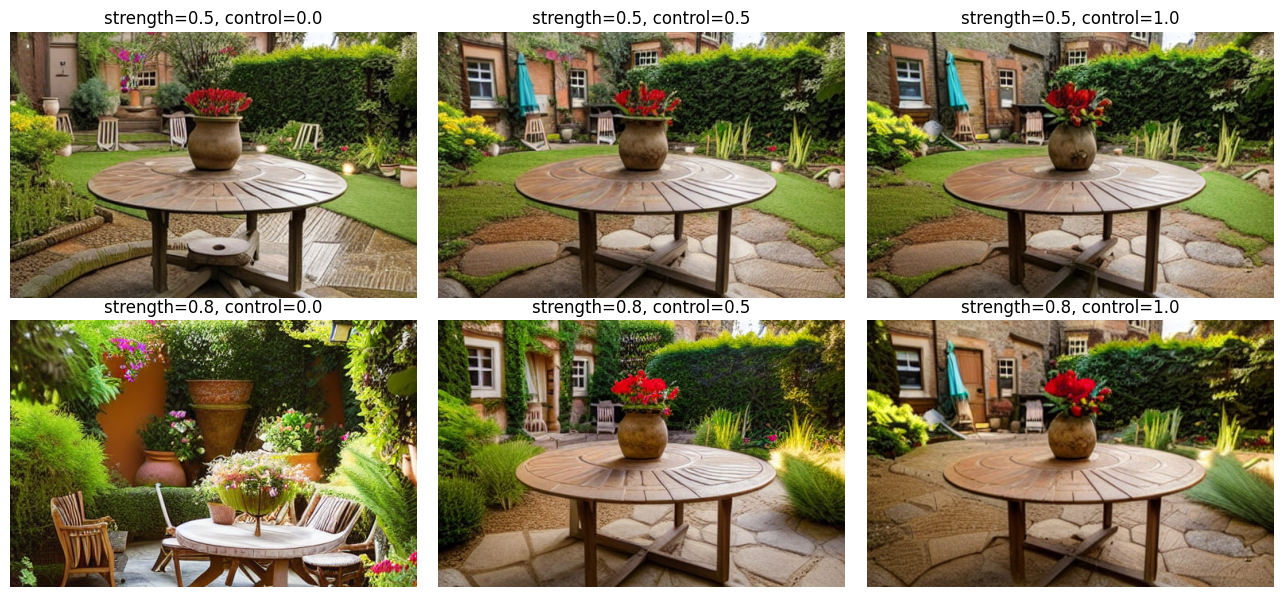

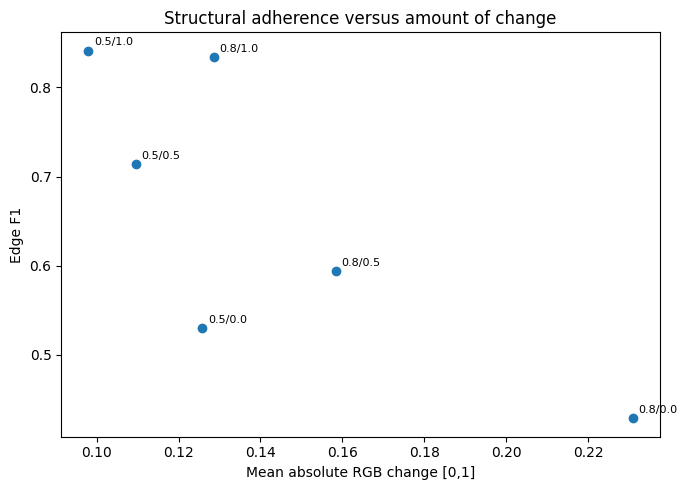

In [22]:
QOUT = Path('question_results'); QOUT.mkdir(exist_ok=True)
comparison_rows = []
for strength in [0.50, 0.80]:
    reference_f1 = student_edge_scores(source, images[(strength, 0.0)])[2]
    for scale in [0.0, 0.5, 1.0]:
        score = student_edge_scores(source, images[(strength, scale)])[2]  # ###YOUR CODE HERE###
        delta = score - reference_f1  # ###YOUR CODE HERE###
        rgb_change = np.abs(np.asarray(images[(strength, scale)], dtype=np.float32) / 255.0
                            - np.asarray(source, dtype=np.float32) / 255.0).mean()  # ###YOUR CODE HERE###
        if score is None or delta is None or rgb_change is None:
            raise NotImplementedError('Complete all three Q2.1 calculations before exporting results.')
        comparison_rows.append(dict(strength=strength, control_scale=scale, edge_f1=score, delta_vs_no_control=delta, mean_rgb_change=float(rgb_change)))
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(QOUT/'controlled_comparison.csv', index=False)
display(comparison)
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for row, strength in enumerate([0.50, 0.80]):
    for col, scale in enumerate([0.0, 0.5, 1.0]):
        axes[row,col].imshow(images[(strength, scale)])
        axes[row,col].set_title(f'strength={strength}, control={scale}')
        axes[row,col].axis('off')
plt.tight_layout(); fig.savefig(QOUT/'controlled_comparison.png', dpi=120); plt.show()
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(comparison['mean_rgb_change'],comparison['edge_f1'])
for r in comparison.itertuples():
    ax.annotate(f'{r.strength}/{r.control_scale}',(r.mean_rgb_change,r.edge_f1),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set(xlabel='Mean absolute RGB change [0,1]',ylabel='Edge F1',title='Structural adherence versus amount of change')
fig.tight_layout();fig.savefig(QOUT/'structure_vs_change.png',dpi=120);plt.show()


**Q2.1 observation:** Does higher structural agreement coincide with less RGB change? What changes as control increases in each row? Refer to the saved images.

**Your answer:**

**Yes, within each row.** As the ControlNet scale goes 0.0 → 0.5 → 1.0, edge F1 rises and RGB change falls:
- strength 0.50: F1 0.530 → 0.714 → 0.841 (Δ vs no-control +0.184, +0.312); RGB change 0.126 → 0.110 → 0.098
- strength 0.80: F1 0.428 → 0.594 → 0.834 (Δ +0.165, +0.405); RGB change 0.231 → 0.158 → 0.129

Control matters more at high strength (+0.405 vs +0.312), because at 0.80 most of the image is re-noised and the Canny map is the main thing still holding the layout.

**Visual, within the 0.80 row:** at control 0.0 the scene is replaced. A terracotta wall, pots and new chairs appear, and the round wooden table becomes a smaller white table lower in the frame. At 0.5 the round table, the cross-shaped base, the vase and the paving layout return, with warmer light and new planting. At 1.0 the layout is almost the original garden, including the house and the umbrella.

The trade-off is not strictly one-to-one across rows. 0.80/1.0 has almost the same F1 as 0.50/1.0 (0.834 vs 0.841) but more RGB change (0.129 vs 0.098), so strong control keeps the edges while still letting colour and lighting change.

### Q2.2 Metric robustness (6 pts)

Complete the scores at tolerance radii **1, 2 and 3** pixels while keeping the generated images fixed (**4 pts**). In the answer below, report whether the ranking changes and explain why increasing a tolerance does not improve an image (**2 pts**).

In [23]:
sensitivity = []
for strength, scale in configs:
    values = [student_edge_scores(source, images[(strength, scale)], radius=r)[2] for r in (1, 2, 3)]  # ###YOUR CODE HERE###
    sensitivity.append(dict(strength=strength, control_scale=scale, f1_r1=values[0], f1_r2=values[1], f1_r3=values[2]))
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(QOUT/'tolerance_sensitivity.csv', index=False)
display(sensitivity)


,strength,control_scale,f1_r1,f1_r2,f1_r3
0,0.5,0.0,0.374646,0.529740,0.614314
1,0.5,0.5,0.564746,0.713722,0.775391
2,0.5,1.0,0.722608,0.841251,0.885059
3,0.8,0.0,0.289281,0.428479,0.503039
4,0.8,0.5,0.448333,0.593776,0.665609
5,0.8,1.0,0.716355,0.833635,0.878909


**Q2.2 observation:** Does the ranking change across the three tolerances? Why does a higher tolerance not improve image quality?

**Your answer:**

**The ranking does not change.** At r = 1, 2 and 3 the order is the same: 0.5/1.0 > 0.8/1.0 > 0.5/0.5 > 0.8/0.5 > 0.5/0.0 > 0.8/0.0. Every score rises with the radius (0.8/0.0: 0.289 → 0.428 → 0.503) because a looser tolerance counts slightly shifted edges as matches. The images are identical in all three columns; only the measuring rule became more lenient, so a higher tolerance cannot make an image better. Note that the top two differ by less than 0.01 at every radius, so they are effectively tied.

### Q2.3 Short answer (4 pts)

Why can a high edge F1 be misleading when choosing a garden design? Name one complementary observation.

**Your answer:**

Edge F1 only measures whether the *outlines* stay in the same place. It ignores colour, materials, realism and whether the prompt was followed. In our results the highest-F1 image (0.5/1.0, F1 0.841) is the one that looks most like the original English garden and least like a Mediterranean courtyard, so a high F1 can simply mean "barely changed".

**Complementary observation:** check prompt compliance visually (terracotta accents, climbing flowers, warm light), or use a text–image score such as CLIP similarity. Also look for artefacts (smears, distorted furniture).

---

## Q3 — Failure analysis and local evaluation (18 pts)

Use your generated images to support each observation.

### Q3.1 Failure cases (6 pts)

Select **two** generated images with different failure modes. Plot the same crop from the input and both outputs. Identify one visible failure in each and discuss one possible cause.

**Your answer:**

**Selected: (0.80, 0.0) and (0.80, 1.0)**, both shown on the same table crop as the input.

- **(0.80, 0.0): structure loss / hallucinated geometry.** The round dark wooden table becomes a smaller white table in a different position. The vase is replaced by a flower basket on a stand, and new chairs appear (table-crop F1 only 0.385). *Cause:* with no ControlNet, strength 0.80 re-noises most of the image, so the text prompt dominates and the original photo barely constrains the result.
- **(0.80, 1.0): under-editing plus texture artefacts.** The layout is kept (table-crop F1 0.862), but the Mediterranean prompt is hardly visible: no terracotta and few climbing flowers. The paving looks over-sharpened and painterly, and grass blades smear along the right edge. *Cause:* scale 1.0 forces the model to reproduce every Canny edge, including clutter such as the child's slide, which fights the prompt. At high strength, textures are re-synthesised inside fixed outlines and look artificial.

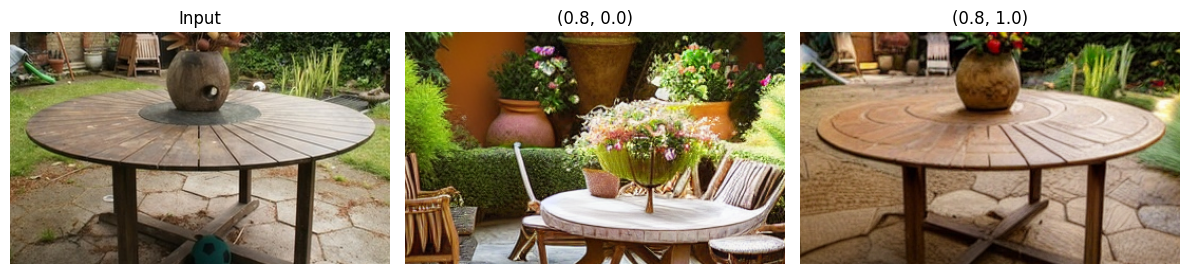

In [24]:
selected = [(0.80, 0.0), (0.80, 1.0)]  # Change after inspecting your outputs.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, label in zip(axes, [source]+[images[k] for k in selected], ['Input']+[str(k) for k in selected]):
    ax.imshow(student_crop(im, TABLE_BOX)); ax.set_title(label); ax.axis('off')
plt.tight_layout(); fig.savefig(QOUT/'failure_cases.png', dpi=120); plt.show()


### Q3.2 Local evaluation (8 pts)

The baseline scores the whole image. Add **one local evaluation** on the same table crop and compare the ranking with the full-image F1. Report what changed and why a local check may help a designer.

**Your answer:**

I recomputed edge F1 (r = 2) using only the shared table crop `TABLE_BOX = (80, 100, 440, 320)` for the input and every output, and compared ranks (`local_vs_global.csv`).

**What changed:** the top two swap. **0.8/1.0 moves from #2 to #1** (table F1 0.862, precision 0.877), and 0.5/1.0 drops to #2 (0.837). Ranks 3–6 are unchanged. 0.8/0.0 is even worse locally (0.385) than globally (0.428), because the table itself is what it destroyed.

**Why:** at strength 0.8 with full control the table keeps its outline, but the background (foliage, grass, house) is repainted more, which pulls the whole-image score down. A whole-image F1 mixes in thousands of foliage edges that a designer does not care about. A local check measures whether the **key object**, the furniture the client wants to keep, survived.

Save your results under `QOUT` so they enter `question_results.zip`: `QOUT/'local_vs_global.csv'`.

,strength,control_scale,full_f1,table_precision,table_recall,table_f1,full_rank,table_rank,rank_change
0,0.5,0.0,0.530,0.518,0.672,0.585,5,5,0
1,0.5,0.5,0.714,0.706,0.791,0.746,3,3,0
2,0.5,1.0,0.841,0.785,0.897,0.837,1,2,-1
3,0.8,0.0,0.428,0.323,0.475,0.385,6,6,0
4,0.8,0.5,0.594,0.639,0.721,0.677,4,4,0
5,0.8,1.0,0.834,0.877,0.847,0.862,2,1,1


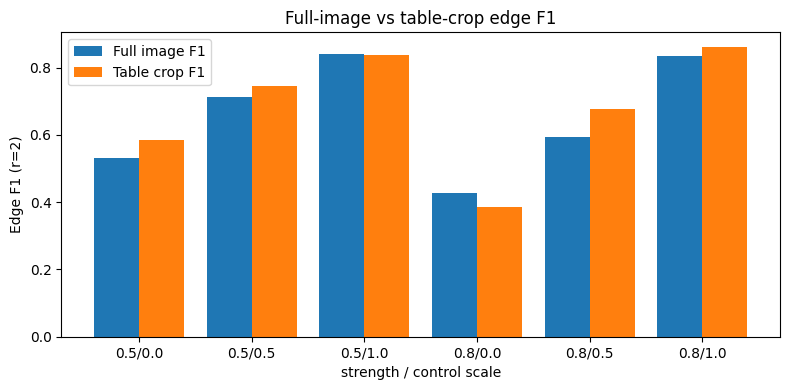

In [25]:
# Implement the local evaluation described above.
# ###YOUR CODE HERE###
# Same edge metric, but computed only inside the shared tabletop crop (TABLE_BOX),
# so background foliage cannot dominate the score.
local_rows = []
source_crop = student_crop(source, TABLE_BOX)
for strength, scale in configs:
    out = images[(strength, scale)]
    _, _, full_f1 = student_edge_scores(source, out)
    lp, lr, local_f1 = student_edge_scores(source_crop, student_crop(out, TABLE_BOX))
    local_rows.append(dict(strength=strength, control_scale=scale,
                           full_f1=full_f1, table_precision=lp, table_recall=lr, table_f1=local_f1))
local_vs_global = pd.DataFrame(local_rows)
local_vs_global['full_rank'] = local_vs_global['full_f1'].rank(ascending=False, method='min', na_option='bottom').astype(int)
local_vs_global['table_rank'] = local_vs_global['table_f1'].rank(ascending=False, method='min', na_option='bottom').astype(int)
local_vs_global['rank_change'] = local_vs_global['full_rank'] - local_vs_global['table_rank']
local_vs_global.to_csv(QOUT/'local_vs_global.csv', index=False)
display(local_vs_global.round(3))

labels = [f'{s}/{c}' for s, c in configs]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, local_vs_global['full_f1'], 0.4, label='Full image F1')
ax.bar(x + 0.2, local_vs_global['table_f1'], 0.4, label='Table crop F1')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set(xlabel='strength / control scale', ylabel='Edge F1 (r=2)', title='Full-image vs table-crop edge F1')
ax.legend(); fig.tight_layout(); fig.savefig(QOUT/'local_vs_global.png', dpi=120); plt.show()


### Q3.3 Responsible use (short, 4 pts)

Name one limitation of presenting these images as a real garden redesign proposal.

**Your answer:**

These images are **not measured or buildable designs**. The model invents materials, plant species, lighting and proportions with no real dimensions, costs, drainage, sun exposure or local climate checks. A client could read them as an achievable proposal. They should be labelled as AI-generated concept mood images, then checked and redrawn by a designer before any decision is made.

---

## Q4 — Design & analysis: beyond the baseline (10 pts)

Write a short paragraph for each question.

### Q4.1 Design choice (4 pts)

**Question:** Choose one of the six settings for a garden designer. Discuss structural preservation, prompt compliance and visible artefacts in a short paragraph.

**Your answer:**

**I would choose strength 0.80, control 0.5.** *Structural preservation:* the round slatted table, its cross-shaped base, the vase and the paving layout are clearly kept (table-crop F1 0.677, overall 0.594), so the client still recognises their garden. *Prompt compliance:* it is a real makeover (RGB change 0.158, more than any other controlled setting), with warm afternoon light, lusher planting and ivy on the house. Terracotta accents are still weak. *Artefacts:* minor ones only, such as a slightly irregular plank pattern on the table top, and none of the grass smears seen at 0.8/1.0. 0.5/1.0 scores higher on F1 but barely changes the garden, and 0.8/0.0 discards the table. If the brief required the layout to be preserved exactly, I would fall back to 0.8/1.0 and accept its weaker styling.

### Q4.2 Beyond Canny conditioning (4 pts)

**Question:** Could depth conditioning or inpainting help this task? For each, give one use and one limitation.

**Your answer:**

**Depth conditioning.** *Use:* it fixes the 3-D layout (table position, ground plane, distance to the house) without locking every fine texture edge, so materials and planting can change more freely than with Canny. *Limitation:* monocular depth is coarse on thin structures such as table legs and foliage, so fine details can drift, and depth does not say what an object is.

**Inpainting.** *Use:* mask only the regions to redesign (lawn, borders, back wall) and keep the table and house pixel-exact. *Limitation:* it needs a hand-made mask, and seams or lighting mismatches can appear at the mask border. A global change like "warm afternoon sunlight" cannot be applied coherently to the unmasked parts.

### Q4.3 Synthesis (2 pts)

**Question:** With one free-GPU session left, which one controlled follow-up would you try, and why?

**Your answer:**

**A multi-seed repeat of the strength-0.80 row** (scales 0.0 / 0.5 / 1.0 × 4 seeds = 12 images, a few minutes on a T4), reporting mean ± std edge F1 and table-crop F1. Every conclusion above rests on a single seed (42), and the top two settings differ by less than 0.01 F1. Repeating seeds tests whether "more control → more structure" and my choice of 0.8/0.5 hold up, or are just luck of one noise sample, while keeping prompt, steps and guidance fixed.

### Export question results

Run after completing Q1–Q3, then download `question_results.zip` from the Colab file pane. The earlier baseline ZIP does not include these question results. Written answers remain in your completed notebook.

In [26]:
import shutil
question_archive = shutil.make_archive('question_results','zip',QOUT)
print('Saved',question_archive)


Saved /content/question_results.zip


### References
- [Mip-NeRF 360 real capture](https://jonbarron.info/mipnerf360/)
- [ControlNet paper and code](https://github.com/lllyasviel/ControlNet)
- [ControlNet Canny model card](https://huggingface.co/lllyasviel/control_v11p_sd15_canny)
- [SD 1.5 model card and licence](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)
- [Diffusers ControlNet documentation](https://huggingface.co/docs/diffusers/en/api/pipelines/controlnet)

Use the pretrained weights under their model-card terms.

In [27]:
# Download both result ZIPs (Colab only)
try:
    from google.colab import files
    files.download('garden_makeover_submission.zip'); files.download('question_results.zip')
except ImportError:
    print('Not in Colab - zips are in the working directory.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>